# 03 - Feature Engineering
Features are created in `utils.build_features` (so the dashboard can reuse them). Groups:

| Group | Examples |
|---|---|
| AQI memory | lags 0-14, rolling means/std, 3-day trend |
| Pollutants | PM2.5, PM10, NO2, SO2, CO, O3, PM2.5/PM10 ratio |
| Traffic proxies | NO2 vs its 28-day norm, CO mean, weekend flag |
| Meteorology | temp, humidity, wind, rain, pressure and their changes |
| Seasonality | month / day-of-year (sin & cos), weekday |
| Pollution events | days since severe AQI, number of poor days in last 2 weeks, Diwali window, stubble-burning season |

**No leakage:** features at day *t* use only data up to day *t*. Targets are AQI at *t+1, t+2, t+3*.

In [9]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

df = pd.read_csv(CLEAN_PATH, index_col=0, parse_dates=True)

# Predictors can have small gaps: fill gaps of up to 10 days (the target AQI is never filled here)
fill = [c for c in POLLUTANTS + WEATHER if c in df.columns]
df[fill] = df[fill].interpolate(limit=10, limit_area="inside")

X = build_features(df)
data = add_targets(X, df["AQI"])

# Missing-data report. A feature that is mostly empty (e.g. a pollutant this station barely
# measures) would delete most rows, so we drop such features instead of losing the data.
miss = (X.isna().mean() * 100).sort_values(ascending=False)
print("Most-missing features (%):")
print(miss.head(10).round(1))
drop_cols = miss[miss > 25].index.tolist()
print("\nDropping (more than 25% missing):", drop_cols)
feature_cols = [c for c in X.columns if c not in drop_cols]
print(len(feature_cols), "features kept")

Most-missing features (%):
aqi_mean14       97.2
aqi_mean7        95.8
aqi_lag14        95.8
aqi_std7         95.8
aqi_lag7         95.2
aqi_trend3       95.1
aqi_mean3        94.9
aqi_lag3         94.8
aqi_lag2         94.7
traffic_proxy    94.7
dtype: float64

Dropping (more than 25% missing): ['aqi_mean14', 'aqi_mean7', 'aqi_lag14', 'aqi_std7', 'aqi_lag7', 'aqi_trend3', 'aqi_mean3', 'aqi_lag3', 'aqi_lag2', 'traffic_proxy', 'aqi_lag1', 'aqi_lag0', 'pm25_mean3', 'co_mean3', 'no2', 'pm25', 'pm10', 'o3', 'co', 'so2', 'pm_ratio']
20 features kept


In [10]:
# Rows where all kept features exist (targets may still be NaN for the last days - the dashboard uses those)
data = data.dropna(subset=feature_cols)
data = data[feature_cols + [f"y_h{h}" for h in HORIZONS]]
print("Rows with complete features:", len(data), "| from", data.index.min().date(), "to", data.index.max().date())
print("\nRows per year:")
print(data.groupby(data.index.year).size())

data.to_csv(FEATURE_PATH)
with open(MODEL_DIR / "feature_cols.json", "w") as f:
    json.dump(feature_cols, f)
print("\nSaved ->", FEATURE_PATH)

Rows with complete features: 888 | from 2022-09-27 to 2025-03-02

Rows per year:
Date
2022     96
2023    365
2024    366
2025     61
dtype: int64

Saved -> C:\Users\RAJESHWARI SAHU\AQI-Forecasting-System\data\processed\delhi_features.csv


### Which features look related to tomorrow's AQI?

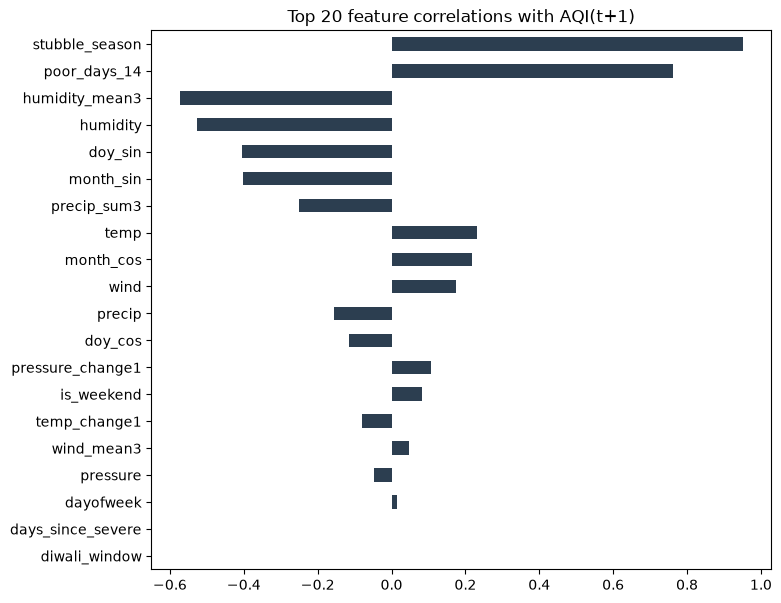

In [11]:
corr = data[feature_cols + ["y_h1"]].corr()["y_h1"].drop("y_h1").sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
corr.head(20)[::-1].plot.barh(ax=ax, color="#2c3e50")
ax.set_title("Top 20 feature correlations with AQI(t+1)")
fig.savefig(FIG_DIR / "feature_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

In [12]:
data[feature_cols].describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
temp,888.0,21.475497,7.567800,6.612500,14.796875,2.215625e+01,28.208333,37.108333
humidity,888.0,71.221988,16.005988,15.083333,64.593750,7.541667e+01,82.135417,94.625000
wind,888.0,6.751337,2.289980,1.875000,5.258333,6.354167e+00,7.969792,25.670833
precip,888.0,1.737050,5.637424,0.000000,0.000000,0.000000e+00,0.600000,81.600000
pressure,888.0,982.262129,6.382476,965.966667,977.081250,9.836208e+02,987.458333,995.470833
wind_mean3,888.0,6.752309,1.795429,2.366667,5.504514,6.436111e+00,7.810764,16.230556
precip_sum3,888.0,5.350000,12.585752,0.000000,0.000000,1.000000e-01,4.500000,128.800000
temp_change1,888.0,-0.010801,1.073781,-4.858333,-0.626042,4.791667e-02,0.645833,3.300000
pressure_change1,888.0,0.003909,1.476131,-4.933333,-0.959375,-6.666667e-02,0.988542,5.191667
humidity_mean3,888.0,71.227086,15.703882,16.833333,65.118056,7.529861e+01,81.958333,93.527778
